# Homography and the 2D minimap

**Author:** Danylo-Makarii Patiuk (Streamlit app and homography). Team: Ivayla Pernikova (data and labelling), Ryan Omondi (error analysis, team clustering), Artem Kucheruk (modeling).

**Goal:** turn pixel boxes from the fine-tuned YOLO model into positions in metres on a top-down 14 x 11 m court, so the Streamlit minimap can show riders and the ball.

**Result:** one fixed 3x3 matrix `H` (the camera never moves) maps every detection. The 5 reference points are reproduced within 0.10-0.13 m on the corners and 0.36 m on the centre spot. 99% of rider points land inside the court.

Code lives in `app/core/homography.py` (the matrix) and `app/core/map_points.py` (detections to map points). This notebook explains and checks it.

## 0. Sources and GenAI use

**Sources**
- Assignment brief `CV_Challenge_2026_2027.pdf` (section 3: 4 or more planar keypoints, `cv2.findHomography`, projection must make spatial sense).
- Court size 14 x 11 m, goals 2 x 2 m: [UCI, What is cycle-ball?](https://www.uci.org/article/what-is-cycle-ball/545EYyXdrXMhOTvuyjR0u3). The French federation rulebook based on UCI rules also gives 14 x 11 m for international matches ([FFC PDF](https://ffc.fr/app/uploads/sites/2/2023/11/Regles-du-polo-velo-en-salle-base-cycle-balle-UCI-1.pdf)). Centre circle and penalty area sizes were not found, so we do not use them.
- OpenCV documentation for `cv2.findHomography` and `cv2.perspectiveTransform` (docs.opencv.org). Not re-read line by line while writing this.
- Team colours (`models/teams.csv`): Ryan's team-clustering notebook (04).
- Error analysis by our teammate (notebook 03): bike confidence about 0.5, ball scores are low.

**What was written by Claude (GenAI) and what by us**
- `tools/pick_points.py`: written by Claude (OpenCV click tool). Danya ran it and clicked every point by hand.
- `app/core/homography.py`: written by Claude, reviewed by Danya.
- `app/core/map_points.py` and `app/core/tracks.py`: written by Claude, reviewed by Danya. The Streamlit wiring in `app/views/analyze.py` was edited by Claude.
- This notebook: drafted by Claude. The reference points in `data/court_keypoints.json`, the choice of 5 points and the decision to use the bike's ground point were made with Danya.
- Claude also explained homography to Danya step by step for the oral exam.

## 1. Setup
We add `app/` to the import path so the notebook uses exactly the same code as the Streamlit app.

In [1]:
import json
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent                      # this notebook lives in notebooks/
sys.path.insert(0, str(ROOT / "app"))

from core.config import COURT_LENGTH, COURT_WIDTH
from core.homography import court_correspondences, get_homography, reprojection_error, to_court
from core.map_points import build_map_points, load_detections

## 2. The idea in plain words

A **homography** is a 3x3 matrix `H` that maps a pixel `(u, v)` on a flat surface to a position `(x, y)` on that surface seen from above. We write the pixel as `(u, v, 1)`, multiply by `H`, and divide by the third number `w` (that division is the perspective).

- `H` has 8 unknowns (the 9th is a free scale). Each point pair gives 2 equations, so **4 pairs is the minimum**. We use 5, so the fit is over-determined and errors average out.
- It is exact only for points **on the floor plane**. A raised point (the ball, a rider's hips) projects too far away. That is why we use the **bottom of the bike box**, where the wheels touch the floor.
- The camera is static, so `H` is computed **once** and reused for all 1,170 frames.

## 3. Reference points

We clicked the points by hand on frame 1 with `tools/pick_points.py`: the 2 far corners, the centre spot, one low point on each end board and two points on the near sideline. The two **near corners are outside the picture**, so each is found where an end line (far corner to low end-board point) crosses the near sideline.

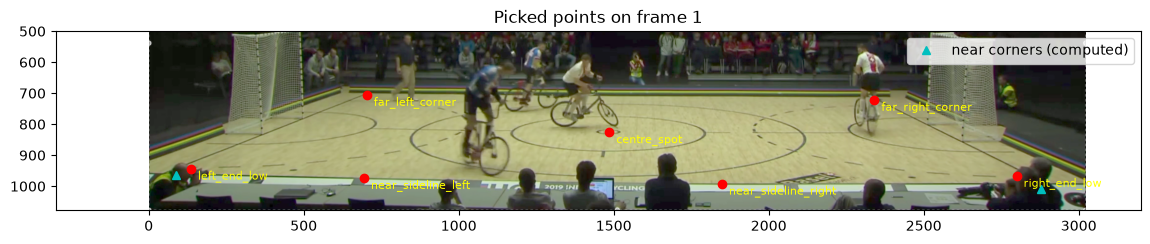

In [2]:
keypoints = json.loads((ROOT / "data" / "court_keypoints.json").read_text())
pixels, metres = court_correspondences()

cap = cv2.VideoCapture(str(ROOT / "data" / "cycle-ball.mp4"))
ok, frame = cap.read()
cap.release()
frame = np.clip(255 * (frame / 255.0) ** 0.6, 0, 255).astype(np.uint8)    # brighten: the hall is dark

fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
for name, (x, y) in keypoints.items():
    ax.plot(x, y, "ro")
    ax.annotate(name, (x, y), color="yellow", fontsize=8, xytext=(5, -8), textcoords="offset points")
near = pixels[2:4]                                                         # computed near corners, may be off-frame
ax.plot(near[:, 0], near[:, 1], "c^", label="near corners (computed)")
ax.set_xlim(-300, 3200); ax.set_ylim(1078, 500); ax.legend(); ax.set_title("Picked points on frame 1")
plt.show()

## 4. Build H and check it

`cv2.findHomography(pixels, metres, 0)` fits `H` to all 5 pairs by least squares (method 0, no outlier rejection, because we trust our clicks). The **reprojection error** is how far each of our own points lands from where it should be.

In [3]:
H = get_homography()
print("H =\n", H.round(5))
for name, err in zip(["far left", "far right", "near right", "near left", "centre spot"], reprojection_error()):
    print(f"{name:12s} error {err:.2f} m")

H =
 [[-1.118000e-02 -2.568000e-02  2.588691e+01]
 [ 8.900000e-04 -8.911000e-02  6.228068e+01]
 [ 0.000000e+00 -3.280000e-03  1.000000e+00]]
far left     error 0.10 m
far right    error 0.12 m
near right   error 0.11 m
near left    error 0.13 m
centre spot  error 0.36 m


**Reading the numbers:** the corners are within about 0.1 m. The centre spot is off by 0.36 m, almost all of it in the depth direction (it lands at 5.9 m instead of 5.5 m). Likely cause: lens distortion bends the near sideline, and the near corners are extrapolated. For a 14 x 11 m map this is not visible, and a lens-distortion fix is beyond the brief, so we accept it and say so in the report.

## 5. From detections to map points

`models/detections.csv` has every box for all 1,170 frames. For each frame we keep riders and the ball:
- **Rider** = a player box paired with a bike box (the rider box must cover at least 30% of the bike box). The map point is the bottom-centre of the **bike** box. If no bike matches, we fall back to the bottom-centre of the player box (about 0.3 m too far, because it is above the floor).
- **Ball** = the most confident ball box per frame, using its box centre. This is only correct when the ball is on the floor.
- Confidence cut-offs: bike and player 0.5 (error analysis), ball 0.25 (the model scores the ball low even when right).

In [4]:
det = load_detections()
mp = build_map_points(det)
print(mp.groupby(["kind", "source"]).size())

riders = mp[mp.kind == "rider"]
print("\nriders per frame:", riders.groupby("frame").size().value_counts().sort_index().to_dict())
inside = riders.x_m.between(-0.5, 14.5) & riders.y_m.between(-0.5, 11.5)
print(f"rider points inside the court (+0.5 m margin): {inside.mean():.1%}")
print(f"frames with a ball: {mp[mp.kind == 'ball'].frame.nunique()} of {det.frame.nunique()}")

kind   source
ball   ball       893
rider  bike      3831
       player     513
dtype: int64

riders per frame: {2: 14, 3: 320, 4: 824, 5: 12}
rider points inside the court (+0.5 m margin): 99.2%
frames with a ball: 893 of 1170


Most frames have 4 riders (2 vs 2), which is what a cycle-ball match has. Frames with 3 or 5 are model errors (a missed rider, or the referee boxed as a player, see notebook 03). About 12% of rider points use the fallback instead of a bike.

## 6. Does it make spatial sense?

Left: every rider point from all frames, which should fill the court and stay inside it. Right: one single frame, riders and ball.

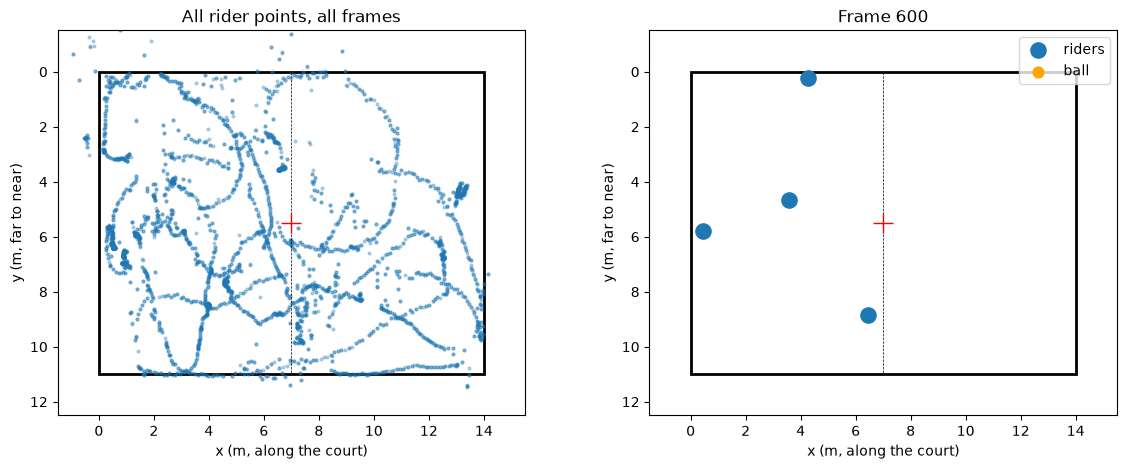

In [5]:
def draw_court(ax):
    ax.add_patch(plt.Rectangle((0, 0), COURT_LENGTH, COURT_WIDTH, fill=False, lw=2))
    ax.plot([COURT_LENGTH / 2] * 2, [0, COURT_WIDTH], "k--", lw=0.5)
    ax.plot(COURT_LENGTH / 2, COURT_WIDTH / 2, "r+", ms=14)
    ax.set_xlim(-1.5, COURT_LENGTH + 1.5); ax.set_ylim(COURT_WIDTH + 1.5, -1.5)   # y down, like the picture
    ax.set_aspect("equal"); ax.set_xlabel("x (m, along the court)"); ax.set_ylabel("y (m, far to near)")

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
draw_court(a)
a.scatter(riders.x_m, riders.y_m, s=4, alpha=0.3)
a.set_title("All rider points, all frames")

draw_court(b)
f = 600
one = mp[mp.frame == f]
b.scatter(one[one.kind == "rider"].x_m, one[one.kind == "rider"].y_m, s=120, label="riders")
b.scatter(one[one.kind == "ball"].x_m, one[one.kind == "ball"].y_m, s=60, c="orange", label="ball")
b.legend(); b.set_title(f"Frame {f}")
plt.show()

## 7. Tracks for the app

The minimap player needs, for each of 2 riders per team and the ball, **one point per video frame** with a stable identity. We have unordered boxes, so `app/core/tracks.py` does three small things:
1. **Team** comes from `models/teams.csv` (blue / white), matched to player boxes. Blue dots are team A, white dots are team B.
2. **Identity:** each team has two slots. Every frame, detections are matched to slots by distance, and a detection that would jump more than 0.5 m (plus 0.1 m per missed frame) is ignored. This removes wrong-team and duplicate boxes.
3. **Gaps:** a missing rider or ball is filled by straight-line interpolation, and the paths get an 11-frame moving average (about 0.25 s) to remove box jitter. The ball is seen in 893 of 1,170 frames, the longest gap is 59 frames (1.3 s), so interpolation makes it visible every frame.

In [6]:
from core.config import SAMPLE_CLIP
from core.tracks import build_tracks
from core.video_io import get_duration

tracks, hz = build_tracks(get_duration(SAMPLE_CLIP))
print(f"{hz} points per second, {len(tracks[0]['points'])} points per track")
for t in tracks:
    p = np.array(t["points"])
    kmh = np.linalg.norm(np.diff(p, axis=0), axis=1) * hz * 3.6
    print(f"{t['name']:5s} {t['kind']:7s} average {kmh.mean():5.1f} km/h, 99th percentile {np.percentile(kmh, 99):5.1f} km/h")

46.784 points per second, 1170 points per track
A1    team-a  average   6.4 km/h, 99th percentile  19.8 km/h
A2    team-a  average   6.8 km/h, 99th percentile  20.3 km/h
B1    team-b  average   7.2 km/h, 99th percentile  20.5 km/h
B2    team-b  average   9.8 km/h, 99th percentile  21.9 km/h
Ball  ball    average   5.9 km/h, 99th percentile  50.1 km/h


**Sanity check:** rider speeds should be plausible for cycle ball (a few to about 25 km/h). Before the jump limit, some tracks showed hundreds of km/h because two riders swapped identity, which is how we found that bug. The ball is faster and noisier because its box is small and interpolated.

## 8. Limits (for the report and the oral)

- **Fixed camera only.** `H` is valid for this clip and angle. Another video needs new reference points.
- **0.4 m depth error** from lens distortion and extrapolated near corners.
- **Ball is not on the floor** when it is lifted, so its map point is too far away then. We keep it, but treat it as approximate.
- **Fallback riders** (no bike matched) are slightly too deep on the map.
- **Detection errors carry through:** a missed or duplicate box becomes a missing or extra dot.
- **Simple tracker:** identity is matched by distance only, so two riders of one team crossing paths can swap.
- **Team colours** come from clustering: about 8% of 4-rider frames do not split 2 v 2 (notebook 04).